# The 12 seconds after a Spurs turnover

Joseph Smarrelli · September 2026 · 2025–26 regular season

A turnover count treats a stolen pass and a shot-clock violation as one lost opportunity each. The defensive problem that follows can be very different. In this Spurs sample, opponents scored 1.05 points in the next 12 game-clock seconds after turnovers linked to a steal, compared with 0.37 after turnovers without a linked steal.

The immediate coaching use is to organize a ball-security and floor-balance review. The result does not tell a player to avoid every risky pass, and it does not identify how many points a different decision would save.



In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import display, Image
from src import turnover_cost
summary = turnover_cost.run()
from src import figures
figures.run()
summary

{'eligible_turnovers': 1007,
 'steal_linked': 582,
 'primary': {'sample': 'All eligible',
  'seconds': 12,
  'estimate': np.float64(0.6862242149655952),
  'lower': np.float64(0.5779121454045955),
  'upper': np.float64(0.7916391433862009),
  'games': 79,
  'events': 1007},
 'groups': [{'kind': 'No linked steal',
   'seconds': 12,
   'events': 425,
   'games': 79,
   'allowed': 0.36705882352941177,
   'lower': 0.29755282679554906,
   'upper': 0.4381264327171633,
   'any_score': 0.16941176470588235},
  {'kind': 'Steal-linked',
   'seconds': 12,
   'events': 582,
   'games': 79,
   'allowed': 1.0515463917525774,
   'lower': 0.9704069344087828,
   'upper': 1.1315345699831365,
   'any_score': 0.49140893470790376}]}

## Results
The following table is regenerated from the pinned inputs.

In [2]:
pd.read_csv('results/turnover_adjusted.csv')

,sample,seconds,estimate,lower,upper,games,events
0,All eligible,8,0.744035,0.641658,0.843294,79,1007
1,All eligible,12,0.686224,0.577912,0.791639,79,1007
2,All eligible,16,0.516512,0.371014,0.654485,79,1007
3,Competitive score and clock,12,0.718940,0.588527,0.839046,75,764
4,No timeout in next 12 seconds,12,0.608546,0.497495,0.711843,79,920


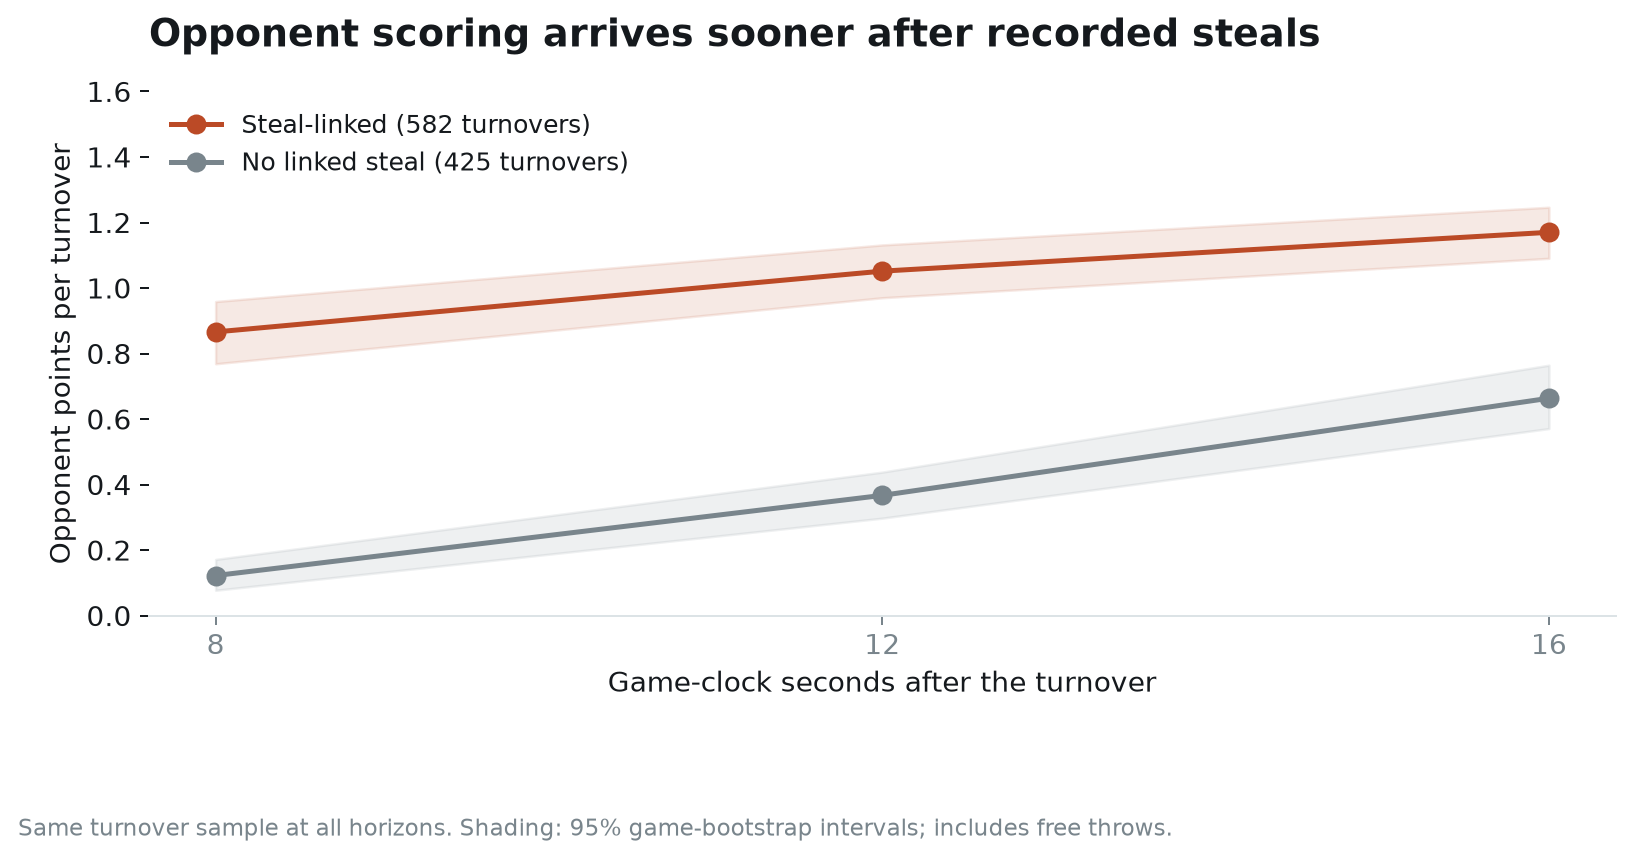

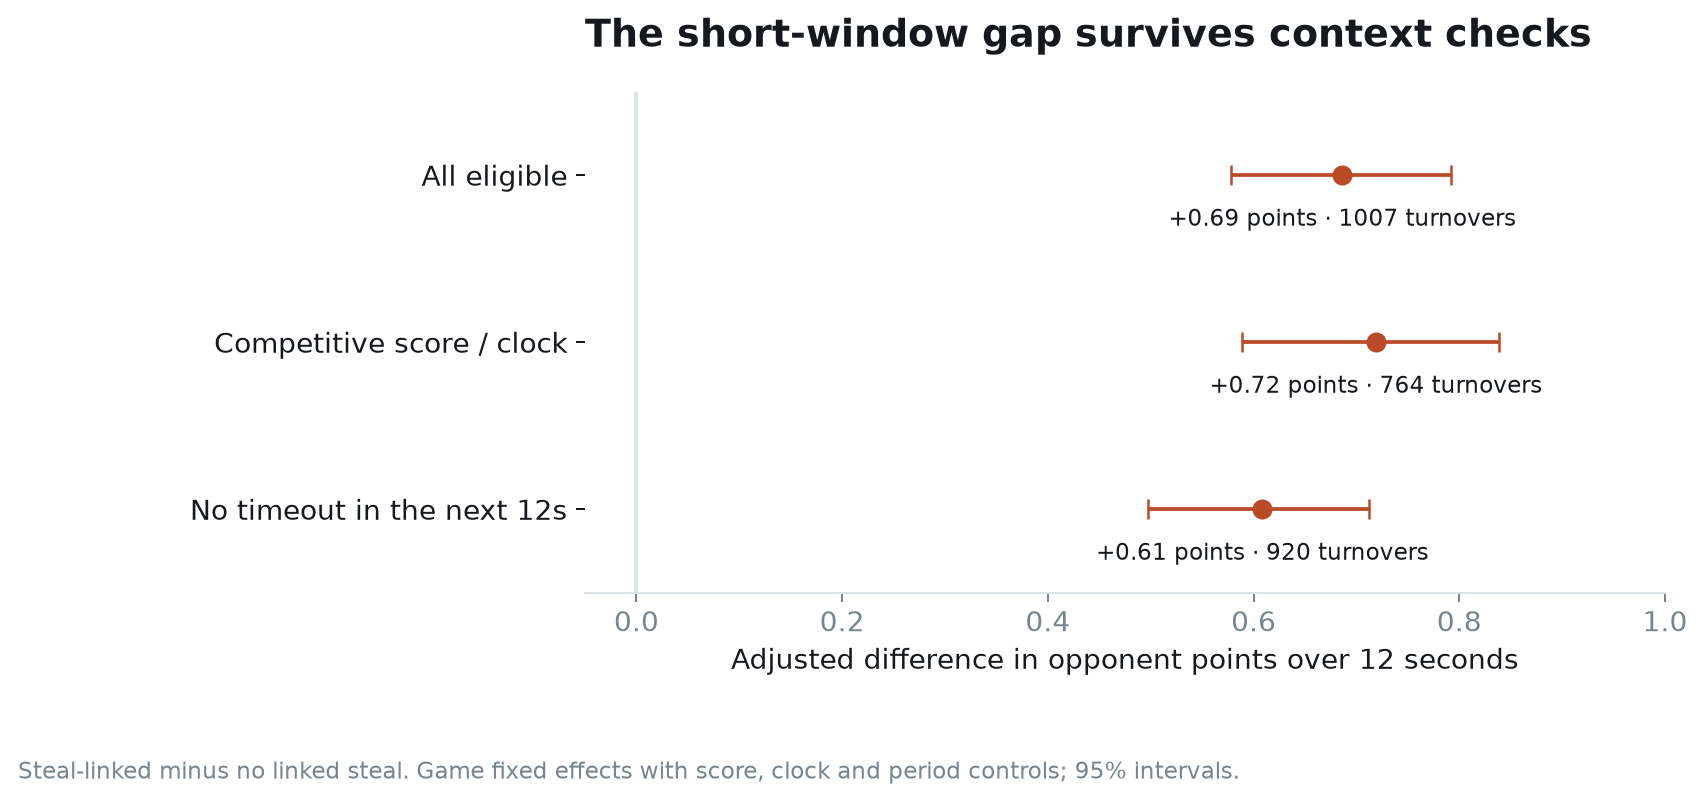

In [3]:
display(Image(filename='figures/turnover_clock.png'))
display(Image(filename='figures/turnover_adjusted.png'))

## Check source exclusions and window boundaries
Scoring is cumulative across horizons. The selected review queue contains adverse examples rather than representative film coding.

In [4]:
display(pd.read_csv('results/game_audit.csv').query("status != 'valid'"))
d = pd.read_csv('data/turnovers.csv.gz')
assert d.allowed_12.ge(d.allowed_8).all() and d.allowed_16.ge(d.allowed_12).all()
display(d.groupby('kind')[['allowed_8','allowed_12','allowed_16']].mean())
display(pd.read_csv('results/turnover_review_queue.csv').head(8))

,game_id,status,events,spurs_points,opponent_points
51,22500788,shot feeds disagree,506,126.0,113.0
69,22501041,score decreased,532,136.0,111.0
76,22501146,score decreased; unexplained score jump,499,115.0,102.0


,allowed_8,allowed_12,allowed_16
kind,,,
No linked steal,0.122353,0.367059,0.663529
Steal-linked,0.865979,1.051546,1.170103


,game_id,event_id,period,seconds,date,margin,opponent,kind,player,player_id,subtype,allowed_8,scored_8,allowed_12,scored_12,allowed_16,scored_16,steal_event_id,timeout_12,live
0,22500141,520,4,619.0,2025-10-30,13.0,MIA,Steal-linked,Barnes,203084,Bad Pass,0.0,0.0,4.0,0.0,4.0,0.0,520,0,1
1,22500010,293,2,198.0,2025-12-25,14.0,OKC,Steal-linked,Castle,1642264,Bad Pass,3.0,0.0,3.0,0.0,3.0,0.0,293,0,1
2,22500032,218,2,456.0,2025-11-07,-4.0,HOU,Steal-linked,Castle,1642264,Lost Ball,3.0,0.0,3.0,0.0,3.0,0.0,218,1,1
3,22500047,259,2,395.0,2025-11-14,2.0,GSW,Steal-linked,Castle,1642264,Bad Pass,3.0,0.0,3.0,0.0,3.0,0.0,259,1,1
4,22500105,15,1,630.0,2025-10-26,0.0,BKN,Steal-linked,Barnes,203084,Bad Pass,3.0,0.0,3.0,0.0,3.0,0.0,15,0,1
5,22500105,490,3,266.0,2025-10-26,14.0,BKN,Steal-linked,Vassell,1630170,Bad Pass,3.0,0.0,3.0,0.0,3.0,0.0,490,0,1
6,22500118,333,2,19.9,2025-10-27,22.0,TOR,Steal-linked,Castle,1642264,Bad Pass,3.0,0.0,3.0,0.0,3.0,0.0,333,0,1
7,22500118,363,3,650.0,2025-10-27,19.0,TOR,Steal-linked,Barnes,203084,Bad Pass,3.0,0.0,3.0,0.0,3.0,0.0,363,0,1


## Interpretation and limits
Read the complete accompanying article for denominators, uncertainty, model selection, and the basketball decisions this analysis cannot identify. The results here are historical research, not a claim of team deployment.